# NLP Task 1

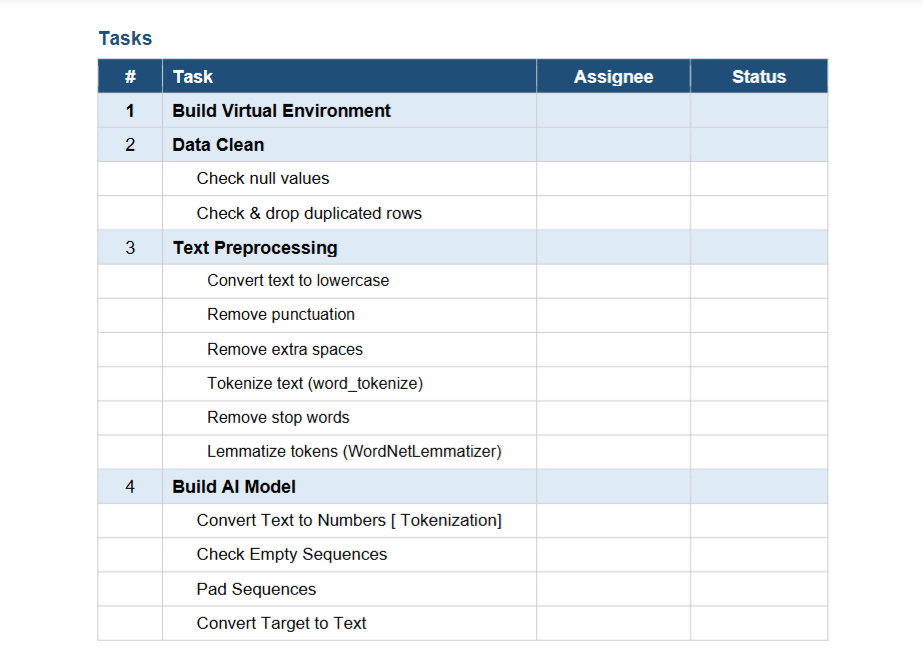

# 1. Build Virtual Environment

 create Virtual Environment using conda


In [269]:
# Create a new conda environment for NLP tasks
#conda create --name nlp_tasks

In [270]:
# Activate the NLP tasks environment
#conda activate nlp_tasks

## Setup

In [271]:
#!pip install pandas
#!pip install numpy
#!pip install matplotlib
#!pip install nltk



#!pip install tensorflow
#!pip install google
%pip install scikit-learn

In [272]:
import  pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import string


import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')
nltk.download('omw-1.4')



from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences


from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## - Data

In [273]:
test=pd.read_csv("/content/test (1).csv")
df = pd.read_csv("/content/train (1).csv")
df.sample(15)

,id,keyword,location,text,target
2644,3796,destruction,NaN,So you have a new weapon that can cause un-ima...,1
2227,3185,deluge,NaN,The f$&amp;@ing things I do for #GISHWHES Just...,0
5448,7769,police,UK,DT @georgegalloway: RT @Galloway4Mayor: ÛÏThe...,1
132,191,aftershock,NaN,Aftershock back to school kick off was great. ...,0
6845,9810,trauma,"Montgomery County, MD",in response to trauma Children of Addicts deve...,0
5559,7934,rainstorm,NaN,@Calum5SOS you look like you got caught in a r...,0
1765,2538,collision,NaN,my favorite lady came to our volunteer meeting...,1
1817,2611,crashed,NaN,@brianroemmele UX fail of EMV - people want to...,1
6810,9756,tragedy,"Los Angeles, CA",Can't find my ariana grande shirt this is a f...,0
4398,6254,hijacking,"Athens,Greece",The Murderous Story Of AmericaÛªs First Hijac...,1


In [274]:
#from google.colab import sheets
#sheet = sheets.InteractiveSheet(df=df)

#2. Data Clean

Check null values

In [275]:
df.isnull().sum()

,0
id,0
keyword,61
location,2533
text,0
target,0


## Fill null values With NAN (thoses not important)

In [276]:
df.fillna("NAN", inplace=True)

## Check again after filling

In [277]:
df.isnull().sum()

,0
id,0
keyword,0
location,0
text,0
target,0


Check & drop duplicated rows

In [278]:
df.duplicated().sum()

np.int64(0)

### Check if there is same tweet (duplicated tweets)?

In [279]:
df.duplicated('text').sum()

np.int64(110)

### Show all duplicated tweets

In [280]:
#duplicated_df = df[df.duplicated('text', keep=False)].sort_values(by='text')
#sheet = sheets.InteractiveSheet(df=duplicated_df)

### Remove Duplicates

In [281]:
resolved_targets = (
    df.groupby('text')['target']
    .mean()
    .apply(lambda mean_val: 1 if mean_val >= 0.5 else 0)
)
df['target'] = df['text'].map(resolved_targets)
df.drop_duplicates(subset=['text'], keep='first', inplace=True)
df.reset_index(drop=True, inplace=True)

In [282]:
df.duplicated('text').sum()

np.int64(0)

In [283]:
df.shape

(7503, 5)

#3. Text Preprocessing

Convert text to lowercase

In [284]:
df['text'] = df['text'].str.lower()

In [285]:
df['text'].sample(15)

,text
1087,@stankyboy88 i should've photo bombed
3191,want to work at swedish health services? we're...
515,we'll crash down like an avalanche
7349,if time heals all wounds how come the belly bu...
699,the blazing elwoods @blazingelwoods - don't bo...
884,'a nightmare on elm street' is getting remade....
7231,be ember aware! http://t.co/lzml1xb2nh
4554,@lenn_len probably. we are inundated with them...
5889,screaming in 22 different languages http://t.c...
5379,oops: bounty hunters try to raid phoenix polic...


Remove punctuation

In [286]:
table = str.maketrans('', '', string.punctuation)

# Apply translation directly to the 'text' column
df['text'] = df['text'].astype(str).str.translate(table)
df['text'].sample(15)

,text
6862,man my stomach feel like a tsunami
6454,planted 390 years ago it was moved to us this ...
4140,breaking arsenals hector bellerin has been arr...
352,but if you build an army of 100 dogs and their...
4884,httptcohfqlwo1kmy emini sp 500 earnings letdow...
6050,theres a weird siren going off herei hope hunt...
7084,but i will be uploading these videos asap so y...
1829,wce i cant even lie even tho i cant stand her ...
1415,another sad ocean casualtygray whale populatio...
892,bloody hell what a day i havent even really do...


Remove extra spaces

In [287]:
df['text'] = df['text'].astype(str).apply(lambda x: ' '.join(x.split()))
df['text'].head(15)

,text
0,our deeds are the reason of this earthquake ma...
1,forest fire near la ronge sask canada
2,all residents asked to shelter in place are be...
3,13000 people receive wildfires evacuation orde...
4,just got sent this photo from ruby alaska as s...
5,rockyfire update california hwy 20 closed in b...
6,flood disaster heavy rain causes flash floodin...
7,im on top of the hill and i can see a fire in ...
8,theres an emergency evacuation happening now i...
9,im afraid that the tornado is coming to our area


Tokenize text (word_tokenize)

In [288]:
df['text'] = df['text'].astype(str).apply(word_tokenize)

In [289]:
df['text'].sample(15)

,text
3218,"[why, tf, did, i, decide, to, workout, today, ..."
2810,"[angry, woman, openly, accuses, nema, of, stea..."
3095,"[student, electrocuted, to, death, in, school,..."
4609,"[speaking, of, memorable, debates, 60second, k..."
2228,"[businesses, are, deluged, with, invoices, mak..."
5148,"[why, did, god, order, obliteration, of, ancie..."
5082,"[skynews, how, is, this, scum, still, alive, o..."
4653,"[shark, boy, and, lava, girl, for, the, third,..."
2772,"[what, the, hell, is, wrong, with, peoplecommu..."
1871,"[man, crushed, to, death, by, own, car, httptc..."


Remove stop words

In [290]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [291]:
stop_words = set(stopwords.words('english'))

df['text'] = df['text'].apply(
    lambda tokens: [word for word in tokens if word.lower() not in stop_words]
)

df['text'].sample(15)

,text
3652,"[things, fear, organizationsfluctuations, dist..."
2137,"[critters, climate, two, plague, deaths, color..."
6611,"[usnwsgov, special, weather, statement, issued..."
6604,"[hear, thunder]"
2891,"[stephengeorg, hey, stephen, remember, time, d..."
6553,"[rt, abbswinston, zionist, terrorist, kidnappe..."
7326,"[latestnews, police, officer, wounded, suspect..."
2532,"[petchary, cant, say, either, us, displeased, ..."
5702,"[bhramabull, watch, run, jewels, use, facts, d..."
5953,"[england, east, coast, dogger, bank, westward,..."


Lemmatize tokens (WordNetLemmatizer)

---



In [292]:
lemmatizer = WordNetLemmatizer()

df['text'] = df['text'].apply(
    lambda tokens: [lemmatizer.lemmatize(word) for word in tokens]
)


In [293]:
df['text'].sample(15)

,text
3021,"[sismo, 13, 1km, nne, geyser, california, time..."
4000,"[group, florida, forest, service, firefighter,..."
4972,"[rationing, food, water, may, also, become, ne..."
6864,"[hope, tsunami, clear, b4, walk, outside, car]"
7440,"[late, night, mcdonalds, friend, hilarious, al..."
5099,"[prepared, obliterate, rapidly, completely, ev..."
4246,"[usarmy, entered, jagm, project, replace, tow,..."
7084,"[uploading, video, asap, guy, get, see, new, w..."
3329,"[update, bend, fd, say, roofing, co, worker, a..."
829,"[bubblycuteone, ok, ok, okayyyyyy, ima, act, r..."


#4. Build AI Model

Convert Text to Numbers [ Tokenization ]

In [294]:
# Initialize the Tokenizer
tokenizer = Tokenizer(oov_token='<OOV>')

# Fit on the list of lemmatized tokens
tokenizer.fit_on_texts(df['text'])

# Convert text to sequences of integers
df['sequences'] = tokenizer.texts_to_sequences(df['text'])

# Print vocabulary size and sample output
print(f'Vocabulary Size: {len(tokenizer.word_index)}')
display(df[['text', 'sequences']].head(5))

Vocabulary Size: 21280


,text,sequences
0,"[deed, reason, earthquake, may, allah, forgive...","[4072, 446, 162, 68, 1699, 4073, 7]"
1,"[forest, fire, near, la, ronge, sask, canada]","[106, 2, 163, 519, 6092, 6093, 1064]"
2,"[resident, asked, shelter, place, notified, of...","[1541, 1410, 1889, 471, 6094, 317, 191, 1889, ..."
3,"[13000, people, receive, wildfire, evacuation,...","[2569, 11, 4074, 76, 191, 379, 34]"
4,"[got, sent, photo, ruby, alaska, smoke, wildfi...","[32, 1065, 113, 6095, 1700, 185, 76, 6096, 102]"


In [295]:
df.sample(15)

,id,keyword,location,text,target,sequences
3851,5556,flattened,"Baltimore, MD","[photo, beach, earring, beach, jewelry, vacati...",0,"[113, 778, 3058, 778, 5474, 3820, 3058, 190, 1..."
5540,8021,refugees,St PetersburgFL,"[imagine, entire, aisle, dedicated, making, pe...",0,"[1328, 751, 17511, 5844, 502, 11, 35, 3, 17512..."
6560,9547,threat,NAN,"[end, australiaûªs, best, burger, httptcote5t...",0,"[194, 3450, 88, 19510, 19511, 9, 19512]"
2308,3346,demolished,NAN,"[jackmulholland1, think, also, became, marquis...",0,"[10780, 70, 226, 2197, 10781, 4999, 4, 10782, ..."
4473,6466,injured,USA,"[offer, httptcogl3c1vc88p, 8392, deluxe, toile...",1,"[1512, 15432, 15433, 15434, 1611, 958, 15435, ..."
5508,7978,razed,NAN,"[latest, home, razed, northern, california, wi...",1,"[131, 23, 445, 125, 34, 76, 17453, 17454]"
3944,5680,floods,Estados Unidos,"[typhoon, soudelor, approach, 7, killed, 2, mi...",1,"[442, 653, 1678, 596, 60, 15, 240, 41, 1144, 1..."
843,1230,blood,NAN,"[chiefcg, nah, young, blood, cook, gone, im, c...",0,"[7731, 1605, 979, 248, 1466, 1116, 5, 914, 730]"
4232,6100,hellfire,Colorado,"[ianhellfire, said, rude, based, experience, k...",0,"[3943, 169, 14921, 1330, 1593, 3081, 181, 574,..."
7219,10482,wild%20fires,Canada,"[wbcshirl2, yes, god, doessnt, change, say, re...",0,"[20784, 552, 119, 20785, 159, 26, 20786, 161, ..."


In [296]:
df.shape

(7503, 6)

Check Empty Sequences

In [297]:
empty_seqs_count = df['sequences'].apply(lambda x: len(x) == 0).sum()
print(f'Number of empty sequences: {empty_seqs_count}')

if empty_seqs_count > 0:
    display(df[df['sequences'].apply(lambda x: len(x) == 0)].head())

Number of empty sequences: 0


Pad Sequences

In [298]:
# Calculate sequence lengths
seq_lengths = df['sequences'].apply(len)
max_len = int(np.percentile(seq_lengths, 95))
print(f'95th percentile of sequence lengths (selected max_len): {max_len}')

# Pad sequences
X = pad_sequences(df['sequences'], maxlen=max_len, padding='post', truncating='post')
print(f'Shape of input tensor X: {X.shape}')

95th percentile of sequence lengths (selected max_len): 16
Shape of input tensor X: (7503, 16)


Convert Target to Text

In [299]:
# Extract the target labels
y = df['target'].values
print(f'Shape of target array y: {y.shape}')
print(f'Target class distribution:\n{df["target"].value_counts()}')

Shape of target array y: (7503,)
Target class distribution:
target
0    4302
1    3201
Name: count, dtype: int64


In [300]:
train_text = df["text"].apply(lambda tokens: " ".join(tokens))
test_text = test["text"].apply(lambda tokens: " ".join(tokens))

y = df["target"]

In [301]:
X_train, X_valid, y_train, y_valid = train_test_split(
    train_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [302]:
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("svm", LinearSVC(random_state=42))
])

svm_model.fit(X_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=20000, min_df=2,
                                 ngram_range=(1, 2))),
                ('svm', LinearSVC(random_state=42))])

In [303]:
y_valid_pred = svm_model.predict(X_valid)

accuracy = accuracy_score(y_valid, y_valid_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")

Accuracy: 0.7761
Accuracy percentage: 77.61%


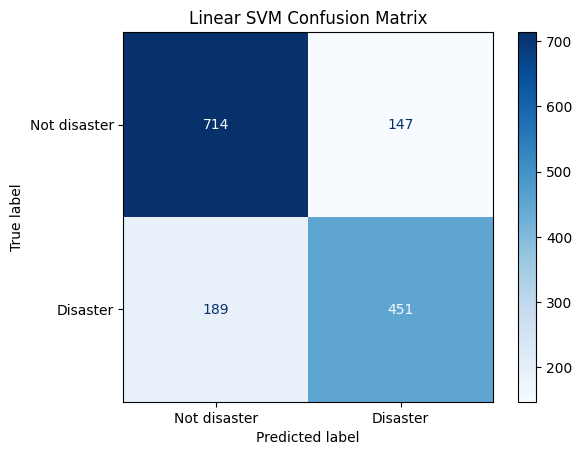

In [304]:
cm = confusion_matrix(y_valid, y_valid_pred)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not disaster", "Disaster"]
)

cm_display.plot(cmap="Blues", values_format="d")
plt.title("Linear SVM Confusion Matrix")
plt.show()

In [305]:
svm_model.fit(train_text, y)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=20000, min_df=2,
                                 ngram_range=(1, 2))),
                ('svm', LinearSVC(random_state=42))])

In [306]:
test_predictions = svm_model.predict(test_text)

print(test_predictions)

[0 0 0 ... 0 0 0]


In [307]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

# Consistent class ordering across all models
CLASS_NAMES = sorted(y_train.unique())
results = []

def evaluate_model(model_name, y_true, y_pred, train_time):
    acc = accuracy_score(y_true, y_pred)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )

    results.append({
        'Model': model_name,
        'Accuracy': acc,
        'Macro Precision': macro_p,
        'Macro Recall': macro_r,
        'Macro F1': macro_f1,
        'Weighted F1': weighted_f1,
        'Train Time (s)': train_time
    })

    print(f"=== {model_name} ===")
    print(f"Train Time: {train_time:.2f}s | Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=CLASS_NAMES)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

In [308]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)


# 2. Keep integer class IDs in sorted order, and convert names to strings
CLASS_IDS = sorted(y_train.unique())
if 'le' in globals() and hasattr(le, 'classes_'):
    CLASS_NAMES = [str(c) for c in le.classes_]
else:
    CLASS_NAMES = [str(c) for c in CLASS_IDS]

results = []

def evaluate_model(model_name, y_true, y_pred, train_time):
    acc = accuracy_score(y_true, y_pred)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )

    results.append({
        'Model': model_name,
        'Accuracy': acc,
        'Macro Precision': macro_p,
        'Macro Recall': macro_r,
        'Macro F1': macro_f1,
        'Weighted F1': weighted_f1,
        'Train Time (s)': train_time
    })

    print(f"=== {model_name} ===")
    print(f"Train Time: {train_time:.2f}s | Accuracy: {acc:.4f} | Macro F1: {macro_f1:.4f} | Weighted F1: {weighted_f1:.4f}\n")
    print(classification_report(y_true, y_pred, labels=CLASS_IDS, target_names=CLASS_NAMES, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

=== SVM (LinearSVC) ===
Train Time: 1.15s | Accuracy: 0.7795 | Macro F1: 0.7745 | Weighted F1: 0.7795

              precision    recall  f1-score   support

           0       0.81      0.81      0.81       861
           1       0.74      0.74      0.74       640

    accuracy                           0.78      1501
   macro avg       0.77      0.77      0.77      1501
weighted avg       0.78      0.78      0.78      1501



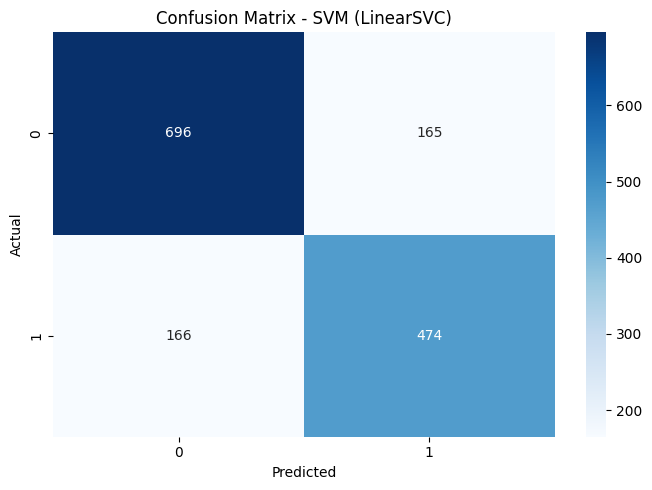

=== Naive Bayes ===
Train Time: 1.06s | Accuracy: 0.8081 | Macro F1: 0.7972 | Weighted F1: 0.8041

              precision    recall  f1-score   support

           0       0.79      0.91      0.84       861
           1       0.84      0.68      0.75       640

    accuracy                           0.81      1501
   macro avg       0.82      0.79      0.80      1501
weighted avg       0.81      0.81      0.80      1501



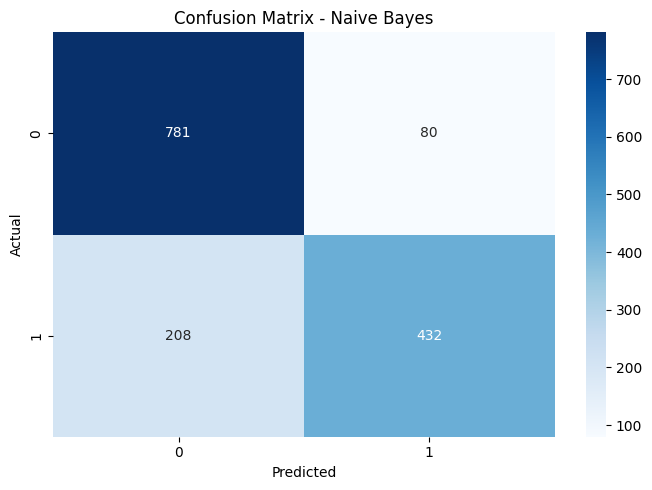

In [309]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# --- Task 3: SVM (LinearSVC) ---
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=20000, sublinear_tf=True)),
    ('svm', LinearSVC(class_weight='balanced', random_state=42))
])

t0 = time.time()
svm_pipeline.fit(X_train, y_train)
svm_time = time.time() - t0

svm_preds = svm_pipeline.predict(X_valid)
evaluate_model("SVM (LinearSVC)", y_valid, svm_preds, svm_time)

# --- Task 4: Multinomial Naive Bayes ---
nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=20000, sublinear_tf=True)),
    ('nb', MultinomialNB(alpha=0.5))
])

t0 = time.time()
nb_pipeline.fit(X_train, y_train)
nb_time = time.time() - t0

nb_preds = nb_pipeline.predict(X_valid)
evaluate_model("Naive Bayes", y_valid, nb_preds, nb_time)

In [310]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout, SpatialDropout1D
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils.class_weight import compute_class_weight

tf.random.set_seed(42)
np.random.seed(42)

# Use your already-encoded integer targets directly
y_train_enc = np.array(y_train)
y_test_enc = np.array(y_valid)
num_classes = len(CLASS_IDS)

# Compute class weights to handle class imbalance fairly
weights = compute_class_weight('balanced', classes=np.unique(y_train_enc), y=y_train_enc)
class_weight_dict = dict(enumerate(weights))

# Tokenize strictly on X_train
MAX_WORDS = 20000
MAX_LEN = 120

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN, padding='post', truncating='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_valid), maxlen=MAX_LEN, padding='post', truncating='post')

def plot_dl_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history['accuracy'], label='Train Accuracy')
    axes[0].plot(history.history['val_accuracy'], label='Val Accuracy')
    axes[0].set_title(f'{model_name} - Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()

    axes[1].plot(history.history['loss'], label='Train Loss')
    axes[1].plot(history.history['val_loss'], label='Val Loss')
    axes[1].set_title(f'{model_name} - Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

def train_and_eval_dl(model, model_name, epochs=12, batch_size=64):
    early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

    t0 = time.time()
    history = model.fit(
        X_train_seq, y_train_enc,
        validation_split=0.1,
        epochs=epochs,
        batch_size=batch_size,
        class_weight=class_weight_dict,
        callbacks=[early_stop],
        verbose=1
    )
    train_time = time.time() - t0

    plot_dl_history(history, model_name)

    probs = model.predict(X_test_seq, verbose=0)
    preds_enc = np.argmax(probs, axis=1)

    evaluate_model(model_name, y_test_enc, preds_enc, train_time)
    return model

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 23s 141ms/step - accuracy: 0.6006 - loss: 0.6449 - val_accuracy: 0.7338 - val_loss: 0.5469
Epoch 2/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 89ms/step - accuracy: 0.8195 - loss: 0.4594 - val_accuracy: 0.7671 - val_loss: 0.5164
Epoch 3/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 91ms/step - accuracy: 0.9058 - loss: 0.2755 - val_accuracy: 0.7720 - val_loss: 0.5389
Epoch 4/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.9476 - loss: 0.1636 - val_accuracy: 0.7637 - val_loss: 0.6873


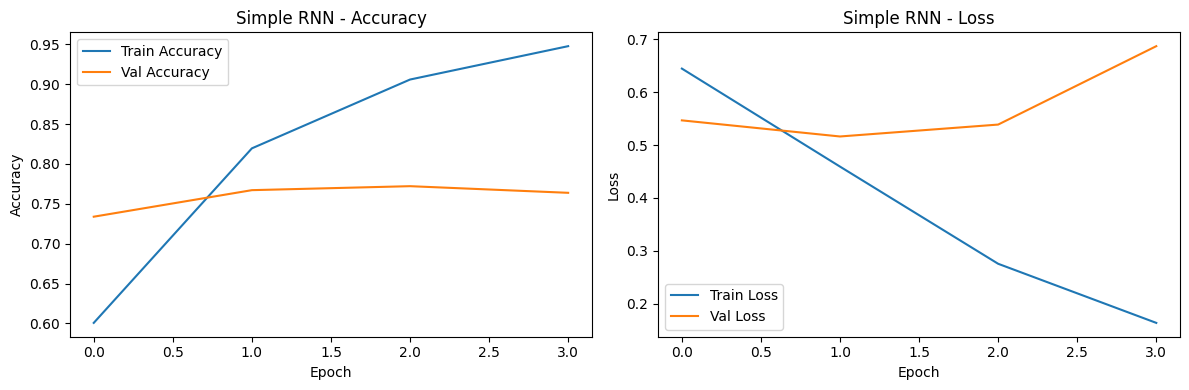

=== Simple RNN ===
Train Time: 53.62s | Accuracy: 0.7795 | Macro F1: 0.7678 | Weighted F1: 0.7755

              precision    recall  f1-score   support

           0       0.77      0.87      0.82       861
           1       0.79      0.65      0.72       640

    accuracy                           0.78      1501
   macro avg       0.78      0.76      0.77      1501
weighted avg       0.78      0.78      0.78      1501



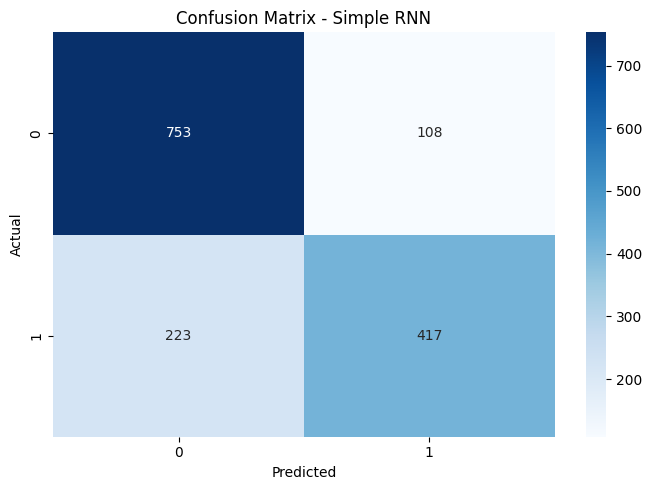

Epoch 1/12


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


85/85 ━━━━━━━━━━━━━━━━━━━━ 21s 172ms/step - accuracy: 0.6140 - loss: 0.6584 - val_accuracy: 0.7404 - val_loss: 0.5327
Epoch 2/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 189ms/step - accuracy: 0.8498 - loss: 0.4036 - val_accuracy: 0.7787 - val_loss: 0.5054
Epoch 3/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 17s 148ms/step - accuracy: 0.9202 - loss: 0.2337 - val_accuracy: 0.7521 - val_loss: 0.5949
Epoch 4/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 13s 154ms/step - accuracy: 0.9543 - loss: 0.1282 - val_accuracy: 0.7438 - val_loss: 0.7300


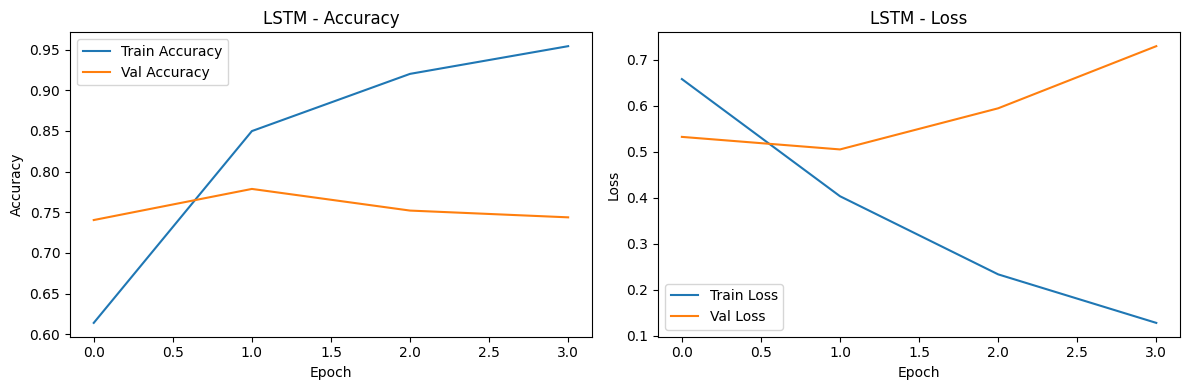

=== LSTM ===
Train Time: 67.04s | Accuracy: 0.7948 | Macro F1: 0.7874 | Weighted F1: 0.7932

              precision    recall  f1-score   support

           0       0.80      0.86      0.83       861
           1       0.79      0.71      0.75       640

    accuracy                           0.79      1501
   macro avg       0.79      0.78      0.79      1501
weighted avg       0.79      0.79      0.79      1501



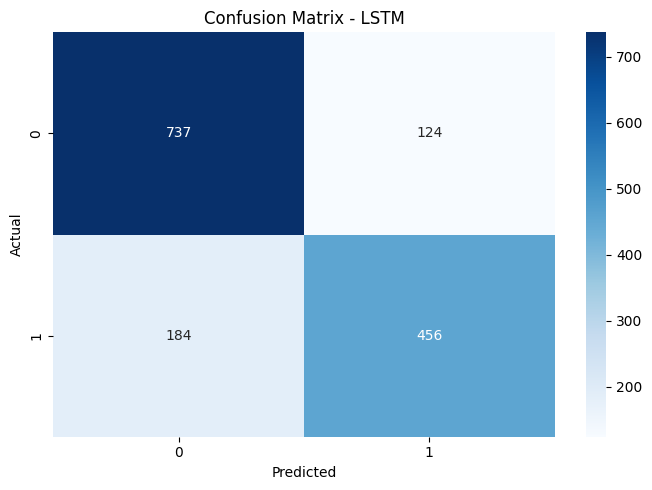

Epoch 1/12


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


85/85 ━━━━━━━━━━━━━━━━━━━━ 22s 190ms/step - accuracy: 0.6110 - loss: 0.6412 - val_accuracy: 0.7720 - val_loss: 0.4787
Epoch 2/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 15s 173ms/step - accuracy: 0.8602 - loss: 0.3556 - val_accuracy: 0.7787 - val_loss: 0.4877
Epoch 3/12
85/85 ━━━━━━━━━━━━━━━━━━━━ 15s 174ms/step - accuracy: 0.9382 - loss: 0.1785 - val_accuracy: 0.7737 - val_loss: 0.5870


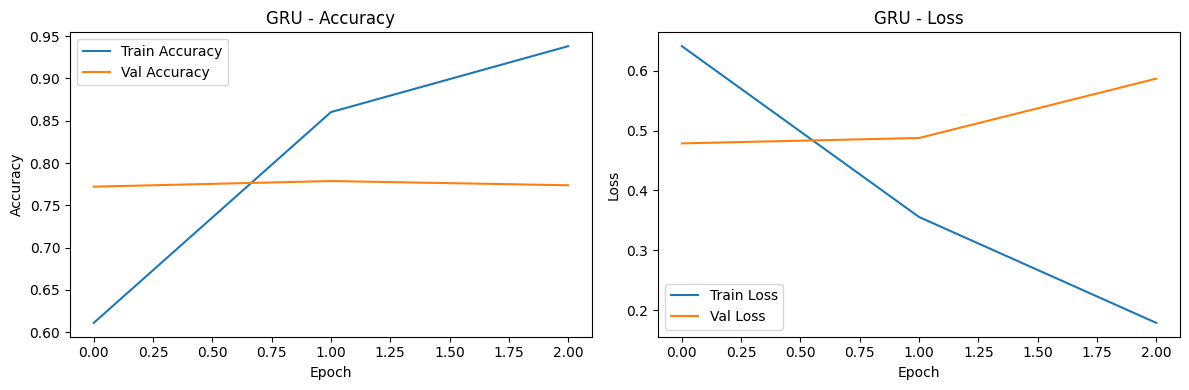

=== GRU ===
Train Time: 51.47s | Accuracy: 0.7955 | Macro F1: 0.7847 | Weighted F1: 0.7918

              precision    recall  f1-score   support

           0       0.78      0.89      0.83       861
           1       0.82      0.67      0.74       640

    accuracy                           0.80      1501
   macro avg       0.80      0.78      0.78      1501
weighted avg       0.80      0.80      0.79      1501



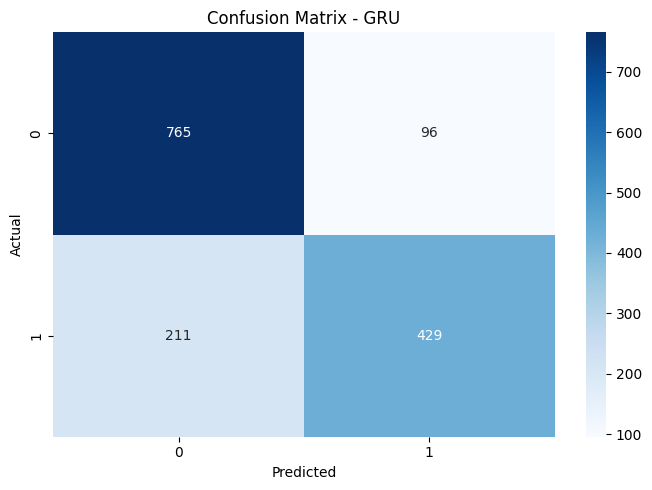

In [311]:
from tensorflow.keras.layers import Bidirectional, GlobalMaxPooling1D
from tensorflow.keras.optimizers import Adam

# 1. Switch to 'pre' padding so the final recurrent step reads real words, not zeros
X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='pre', truncating='pre')
X_test_pad  = pad_sequences(X_test_seq,  maxlen=MAX_LEN, padding='pre', truncating='pre')

# 2. Clean architecture with Bidirectional + GlobalMaxPooling1D (fast cuDNN + strong keyword extraction)
def build_dl_model(layer_type):
    model = Sequential([
        Embedding(input_dim=MAX_WORDS, output_dim=64, input_length=MAX_LEN),
        SpatialDropout1D(0.2),
        Bidirectional(layer_type(32, return_sequences=True)),
        GlobalMaxPooling1D(),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=Adam(learning_rate=1e-3),
        metrics=['accuracy']
    )
    return model

# --- Task 5: Simple RNN ---
rnn_model = build_dl_model(SimpleRNN)
rnn_model = train_and_eval_dl(rnn_model, "Simple RNN")

# --- Task 6: LSTM ---
lstm_model = build_dl_model(LSTM)
lstm_model = train_and_eval_dl(lstm_model, "LSTM")

# --- Task 7: GRU ---
gru_model = build_dl_model(GRU)
gru_model = train_and_eval_dl(gru_model, "GRU")

In [313]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Ensure NLTK resources are available
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Unified Task 1 preprocessing function (preserves not/no/never)
negations = {'not', 'no', 'never', 'nor', 'neither'}
stop_words = set(stopwords.words('english')) - negations
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+|<.*?>', ' ', text)
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = nltk.word_tokenize(text)
    cleaned_tokens = [
        lemmatizer.lemmatize(tok)
        for tok in tokens
        if tok not in stop_words and len(tok) > 1
    ]
    return " ".join(cleaned_tokens)

unseen_texts = [
    # Non-disasters (should predict 0)
    "I had a really productive morning, finished my coffee and went for a run.",
    "Work deadlines are piling up fast this week and I am feeling super overwhelmed.",

    # Disasters (should predict 1)
    "Breaking: Massive 6.8 magnitude earthquake just hit downtown, buildings collapsed and people are trapped.",
    "Wildfire spreading rapidly near the highway, mandatory evacuation ordered for all residents.",
    "Two passenger trains collided near the central station, emergency crews rushing to the scene."
]

# Apply Task 1 preprocessing consistently before vectorization/tokenization
cleaned_unseen = [clean_text(t) for t in unseen_texts]
unseen_seq = pad_sequences(
    tokenizer.texts_to_sequences(cleaned_unseen),
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

# Generate predictions from all five models
svm_unseen = svm_pipeline.predict(cleaned_unseen)
nb_unseen = nb_pipeline.predict(cleaned_unseen)
rnn_unseen = np.argmax(rnn_model.predict(unseen_seq, verbose=0), axis=1)
lstm_unseen = np.argmax(lstm_model.predict(unseen_seq, verbose=0), axis=1)
gru_unseen = np.argmax(gru_model.predict(unseen_seq, verbose=0), axis=1)

# Convert integer IDs back to text labels if your Task 1 LabelEncoder `le` is in memory
if 'le' in globals() and hasattr(le, 'inverse_transform'):
    svm_unseen = le.inverse_transform(svm_unseen)
    nb_unseen = le.inverse_transform(nb_unseen)
    rnn_unseen = le.inverse_transform(rnn_unseen)
    lstm_unseen = le.inverse_transform(lstm_unseen)
    gru_unseen = le.inverse_transform(gru_unseen)

pred_df = pd.DataFrame({
    'Unseen Statement': unseen_texts,
    'Cleaned Text': cleaned_unseen,
    'SVM Prediction': svm_unseen,
    'Naive Bayes Prediction': nb_unseen,
    'Simple RNN Prediction': rnn_unseen,
    'LSTM Prediction': lstm_unseen,
    'GRU Prediction': gru_unseen,
})

print("NOTE: All outputs below are automated NLP text-class predictions, NOT clinical diagnoses.\n")
display(pred_df)

NOTE: All outputs below are automated NLP text-class predictions, NOT clinical diagnoses.



,Unseen Statement,Cleaned Text,SVM Prediction,Naive Bayes Prediction,Simple RNN Prediction,LSTM Prediction,GRU Prediction
0,"I had a really productive morning, finished my...",really productive morning finished coffee went...,0,0,0,0,0
1,Work deadlines are piling up fast this week an...,work deadline piling fast week feeling super o...,0,0,0,0,0
2,Breaking: Massive 6.8 magnitude earthquake jus...,breaking massive magnitude earthquake hit down...,1,1,1,1,1
3,"Wildfire spreading rapidly near the highway, m...",wildfire spreading rapidly near highway mandat...,1,1,1,1,1
4,Two passenger trains collided near the central...,two passenger train collided near central stat...,1,1,1,1,1
